### 1. Încărcarea bibliotecilor și identificarea fișierelor

Pentru început, am importat bibliotecile necesare pentru analiza datelor și am verificat ce fișiere sunt disponibile în datasetul Kaggle.

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/mkechinov/ecommerce-behavior-data-from-multi-category-store/2019-Nov.csv
/kaggle/input/datasets/mkechinov/ecommerce-behavior-data-from-multi-category-store/2019-Oct.csv


### 2. Citirea și explorarea inițială a datelor

Am încărcat primele 100.000 de înregistrări din fișierul pentru octombrie 2019, pentru a vedea cum sunt organizate datele. Am verificat numărul de exemple, numărul de caracteristici și primele rânduri din dataset.

In [2]:
import pandas as pd

fisier = "/kaggle/input/datasets/mkechinov/ecommerce-behavior-data-from-multi-category-store/2019-Oct.csv"

df = pd.read_csv(fisier, nrows=100000)

print("Număr de exemple:", len(df))
print("Număr de caracteristici:", len(df.columns))

df.head()

Număr de exemple: 100000
Număr de caracteristici: 9


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2019-10-01 00:00:00 UTC,view,44600062,2103807459595387724,NaN,shiseido,35.79,541312140,72d76fde-8bb3-4e00-8c23-a032dfed738c
1,2019-10-01 00:00:00 UTC,view,3900821,2053013552326770905,appliances.environment.water_heater,aqua,33.20,554748717,9333dfbd-b87a-4708-9857-6336556b0fcc
2,2019-10-01 00:00:01 UTC,view,17200506,2053013559792632471,furniture.living_room.sofa,NaN,543.10,519107250,566511c2-e2e3-422b-b695-cf8e6e792ca8
3,2019-10-01 00:00:01 UTC,view,1307067,2053013558920217191,computers.notebook,lenovo,251.74,550050854,7c90fc70-0e80-4590-96f3-13c02c18c713
4,2019-10-01 00:00:04 UTC,view,1004237,2053013555631882655,electronics.smartphone,apple,1081.98,535871217,c6bd7419-2748-4c56-95b4-8cec9ff8b80d


### 3. Verificarea structurii datelor și a valorilor lipsă

Am verificat tipurile de date ale celor 9 caracteristici și dacă există valori lipsă. Această analiză mă ajută să înțeleg mai bine datasetul și să identific eventualele probleme care trebuie rezolvate înainte de antrenarea modelelor de învățare automată.

In [3]:
print("Informații despre dataset:")
df.info()

print("\nValori lipsă pentru fiecare caracteristică:")
print(df.isnull().sum())

Informații despre dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   event_time     100000 non-null  object 
 1   event_type     100000 non-null  object 
 2   product_id     100000 non-null  int64  
 3   category_id    100000 non-null  int64  
 4   category_code  67413 non-null   object 
 5   brand          85607 non-null   object 
 6   price          100000 non-null  float64
 7   user_id        100000 non-null  int64  
 8   user_session   100000 non-null  object 
dtypes: float64(1), int64(3), object(5)
memory usage: 6.9+ MB

Valori lipsă pentru fiecare caracteristică:
event_time           0
event_type           0
product_id           0
category_id          0
category_code    32587
brand            14393
price                0
user_id              0
user_session         0
dtype: int64


### 4. Analiza tipurilor de evenimente

Am analizat câte evenimente de fiecare tip există în cele 100.000 de înregistrări din octombrie 2019. Am calculat atât numărul de evenimente, cât și procentul fiecăruia, pentru a observa cât de des utilizatorii vizualizează produse, le adaugă în coș sau le cumpără.

In [4]:
print("Distribuția tipurilor de evenimente:")
print(df["event_type"].value_counts())

print("\nProcente:")
print(df["event_type"].value_counts(normalize=True) * 100)

Distribuția tipurilor de evenimente:
event_type
view        97130
purchase     1655
cart         1215
Name: count, dtype: int64

Procente:
event_type
view        97.130
purchase     1.655
cart         1.215
Name: proportion, dtype: float64


### 5. Reprezentarea grafică a tipurilor de evenimente

Am realizat un grafic cu bare pentru a vizualiza distribuția tipurilor de evenimente din cele 100.000 de înregistrări analizate. Graficul mă ajută să observ mai ușor diferențele dintre numărul de vizualizări, adăugări în coș și achiziții.

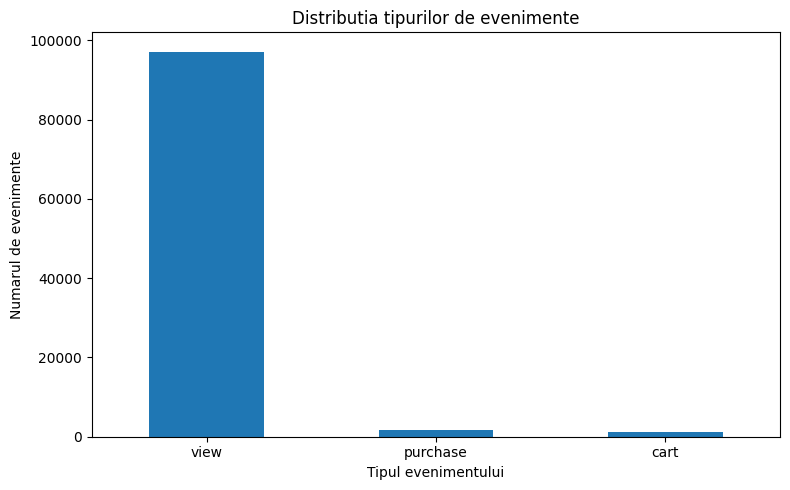

In [5]:
import matplotlib.pyplot as plt

df["event_type"].value_counts().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Distributia tipurilor de evenimente")
plt.xlabel("Tipul evenimentului")
plt.ylabel("Numarul de evenimente")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 6. Crearea unui eșantion din octombrie și noiembrie 2019

Deoarece datasetul original este foarte mare, am selectat câte 50.000 de înregistrări din fiecare lună, folosind citirea datelor pe bucăți. Am combinat apoi cele două eșantioane pentru a obține un set de 100.000 de exemple, pe care îl voi utiliza în continuarea analizei.

In [6]:

import pandas as pd
import numpy as np

baza = "/kaggle/input/datasets/mkechinov/ecommerce-behavior-data-from-multi-category-store/"

def esantion_luna(fisier, n=50000):
    bucati = []
    generator = np.random.default_rng(42)

    for chunk in pd.read_csv(baza + fisier, chunksize=500000):
        selectie = generator.random(len(chunk)) < 0.002
        bucati.append(chunk.loc[selectie])

    esantion = pd.concat(bucati, ignore_index=True)
    return esantion.sample(n=n, random_state=42)

octombrie = esantion_luna("2019-Oct.csv")
noiembrie = esantion_luna("2019-Nov.csv")

df = pd.concat([octombrie, noiembrie], ignore_index=True)

print("Număr total de exemple:", len(df))
print("Număr de caracteristici:", len(df.columns))
print(df["event_type"].value_counts())


Număr total de exemple: 100000
Număr de caracteristici: 9
event_type
view        95045
cart         3372
purchase     1583
Name: count, dtype: int64


### 7. Reprezentarea grafică a evenimentelor din cele două luni

Am realizat un grafic cu bare pentru a analiza distribuția evenimentelor din eșantionul combinat de 100.000 de înregistrări. Graficul arată diferențele dintre numărul de vizualizări, adăugări în coș și achiziții din datele selectate pentru octombrie și noiembrie 2019.

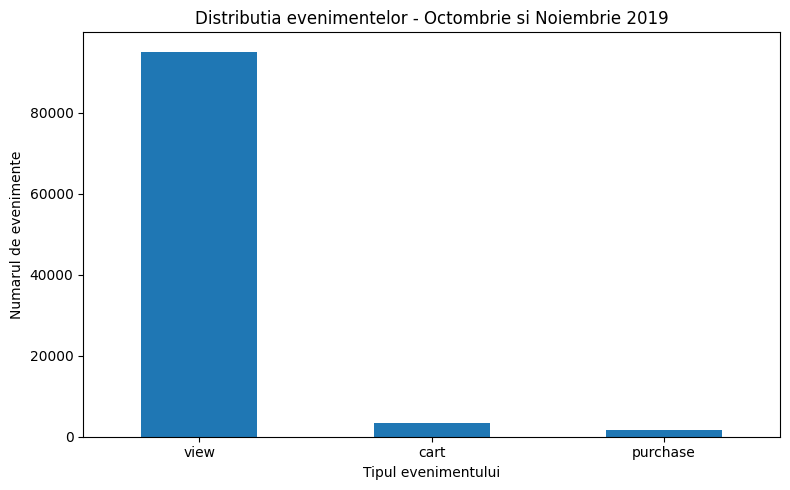

In [7]:
import matplotlib.pyplot as plt

df["event_type"].value_counts().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Distributia evenimentelor - Octombrie si Noiembrie 2019")
plt.xlabel("Tipul evenimentului")
plt.ylabel("Numarul de evenimente")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("/kaggle/working/distributia_evenimentelor.png", dpi=300, bbox_inches="tight")
plt.show()

### 8. Verificarea valorilor lipsă în eșantionul combinat

Am verificat valorile lipsă din eșantionul de 100.000 de înregistrări selectate din octombrie și noiembrie 2019. Această verificare mă ajută să identific caracteristicile care conțin date incomplete și care ar putea necesita prelucrare în etapele următoare ale proiectului.

In [8]:
print(df.isnull().sum())

event_time           0
event_type           0
product_id           0
category_id          0
category_code    31974
brand            14036
price                0
user_id              0
user_session         0
dtype: int64


### 9. Estimarea rezultatelor folosind un eșantion mai mic

În această etapă voi selecta aleatoriu 10.000 de înregistrări din eșantionul de 100.000. Voi calcula distribuția tipurilor de evenimente și voi folosi rezultatele pentru a estima distribuția în cele 100.000 de înregistrări.

Apoi voi compara estimările cu valorile reale și voi calcula erorile, pentru a observa cât de apropiate sunt rezultatele obținute din eșantionul mai mic.

In [9]:

# Selectăm aleatoriu 10.000 de exemple
df_mic = df.sample(n=10000, random_state=42)

# Numărăm evenimentele din eșantionul mic
numar_mic = df_mic["event_type"].value_counts()

# Estimăm numărul evenimentelor pentru 100.000 de exemple
estimare = numar_mic * 10

# Calculăm valorile reale
real = df["event_type"].value_counts()

# Comparăm rezultatele
comparatie = pd.DataFrame({
    "Estimare (din 10.000)": estimare,
    "Real (100.000)": real
}).fillna(0)

comparatie["Eroare absoluta"] = abs(
    comparatie["Estimare (din 10.000)"] -
    comparatie["Real (100.000)"]
)

comparatie["Eroare (%)"] = (
    comparatie["Eroare absoluta"] /
    comparatie["Real (100.000)"] * 100
).round(2)

print(comparatie)


            Estimare (din 10.000)  Real (100.000)  Eroare absoluta  Eroare (%)
event_type                                                                    
view                        95320           95045              275        0.29
cart                         3210            3372              162        4.80
purchase                     1470            1583              113        7.14


### Interpretarea rezultatelor

Am folosit un eșantion aleatoriu de 10.000 de înregistrări pentru a estima distribuția evenimentelor în setul de 100.000 de exemple.

Am comparat estimările cu valorile reale și am calculat erorile procentuale. Rezultatele arată că eroarea pentru vizualizări este de 0,29%, pentru adăugările în coș de 4,80%, iar pentru achiziții de 7,14%.

Observ că estimarea este foarte apropiată de valoarea reală în cazul vizualizărilor. Diferențele sunt mai mari pentru evenimentele mai puțin frecvente, precum adăugările în coș și achizițiile.

Această analiză arată că putem obține estimări utile dintr-un eșantion mai mic, dar precizia poate varia în funcție de frecvența evenimentelor.

# S6 – Verificarea 1: Primul model de Machine Learning

## 1. Obiectivul modelului

În această etapă voi construi prima versiune a unui model de Machine Learning pentru analiza comportamentului clienților dintr-un magazin online.

Scopul este să prezic dacă un utilizator va efectua o achiziție, folosind informații despre interacțiunile sale anterioare cu produsele.

Pentru început, voi pregăti datele, voi împărți exemplele în seturi de antrenare și testare, voi antrena un model de clasificare și voi evalua rezultatele.

Modelul inițial va reprezenta punctul de plecare pentru îmbunătățirile din etapa S9.

In [10]:
# S6 - Verificarea 1
# Verificarea datelor disponibile pentru primul model
print("Variabila df exista:", "df" in globals())
print("Variabile DataFrame:", [n for n, v in globals().items() if isinstance(v, pd.DataFrame)])
print("Variabile disponibile:")
print(df.columns.tolist())

print("\nPrimele 5 inregistrari:")
display(df.head())

Variabila df exista: True
Variabile DataFrame: ['df', '_2', 'octombrie', 'noiembrie', 'df_mic', 'comparatie']
Variabile disponibile:
['event_time', 'event_type', 'product_id', 'category_id', 'category_code', 'brand', 'price', 'user_id', 'user_session']

Primele 5 inregistrari:


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2019-10-11 12:25:39 UTC,view,29100065,2053013565941482475,appliances.personal.massager,gezatone,203.35,554184344,eb561ad8-8ce8-4d98-89dd-c3238488bba4
1,2019-10-11 16:47:31 UTC,view,1004870,2053013555631882655,electronics.smartphone,samsung,285.44,536916271,55365847-52f8-4d4f-b6d1-866277418573
2,2019-10-19 16:35:05 UTC,view,24900170,2053013562183385881,NaN,eurolight,3.32,515271283,66cfe913-b4d6-4a65-8185-e28fee8555d3
3,2019-10-30 13:00:33 UTC,view,1002633,2053013555631882655,electronics.smartphone,apple,385.78,546718708,a5439e0f-5094-4741-8982-1273f644c1ca
4,2019-10-08 18:35:48 UTC,view,1005115,2053013555631882655,electronics.smartphone,apple,1015.46,558184751,05aed021-0319-49ef-b13c-31ac71a2cc65


In [11]:
# S6 - Verificarea dimensiunii datelor si a claselor

print("Numar total de inregistrari:", len(df))

print("\nDistributia tipurilor de evenimente:")
print(df["event_type"].value_counts())

print("\nNumar de utilizatori unici:")
print(df["user_id"].nunique())

print("\nNumar de sesiuni unice:")
print(df["user_session"].nunique())

Numar total de inregistrari: 100000

Distributia tipurilor de evenimente:
event_type
view        95045
cart         3372
purchase     1583
Name: count, dtype: int64

Numar de utilizatori unici:
93989

Numar de sesiuni unice:
99315


In [12]:
# S6 - Verificarea sesiunilor consecutive

fisier_octombrie = (
    "/kaggle/input/datasets/mkechinov/"
    "ecommerce-behavior-data-from-multi-category-store/2019-Oct.csv"
)

coloane = [
    "event_time",
    "event_type",
    "product_id",
    "user_id",
    "user_session"
]

date_s6 = pd.read_csv(
    fisier_octombrie,
    usecols=coloane,
    nrows=200000
)

print("Numar de evenimente:", len(date_s6))

print("\nTipuri de evenimente:")
print(date_s6["event_type"].value_counts())

print("\nSesiuni cu cel putin 2 evenimente:")
numar_evenimente = date_s6.groupby("user_session").size()
print((numar_evenimente >= 2).sum())

print("\nSesiuni cu achizitii:")
print(
    date_s6.loc[
        date_s6["event_type"] == "purchase",
        "user_session"
    ].nunique()
)

Numar de evenimente: 200000

Tipuri de evenimente:
event_type
view        193377
purchase      3639
cart          2984
Name: count, dtype: int64

Sesiuni cu cel putin 2 evenimente:
30353

Sesiuni cu achizitii:
3127


In [13]:
# S6 - Verificarea sesiunilor care pot fi folosite pentru predictie

date_verificare = date_s6.dropna(
    subset=["user_session", "event_time"]
).copy()

date_verificare["event_time"] = pd.to_datetime(
    date_verificare["event_time"],
    utc=True
)

date_verificare = date_verificare.sort_values(
    "event_time",
    kind="stable"
)

# Verificam daca fiecare sesiune contine o achizitie
# si daca exista evenimente inainte de prima achizitie.

def verifica_sesiune(grup):
    achizitii = grup["event_type"].eq("purchase")

    if not achizitii.any():
        return pd.Series({
            "are_achizitie": False,
            "are_istoric_anterior": False
        })

    prima_achizitie = achizitii.to_numpy().argmax()

    return pd.Series({
        "are_achizitie": True,
        "are_istoric_anterior": prima_achizitie > 0
    })

rezultat_sesiuni = date_verificare.groupby(
    "user_session"
).apply(
    verifica_sesiune,
    include_groups=False
)

print("Sesiuni cu achizitie:",
      rezultat_sesiuni["are_achizitie"].sum())

print("Sesiuni cu achizitie si istoric anterior:",
      rezultat_sesiuni["are_istoric_anterior"].sum())

Sesiuni cu achizitie: 3127
Sesiuni cu achizitie si istoric anterior: 3086


In [14]:
# S6 - Construirea primului set de date pentru clasificare

# Pastram sesiunile cu identificator valid
date_model = date_verificare.dropna(
    subset=["user_session"]
).copy()

# Prima interactiune din fiecare sesiune
primele_evenimente = (
    date_model.groupby("user_session", sort=False)
    .first()
    .reset_index()
)

# Eticheta: exista o achizitie ulterior in aceeasi sesiune?
sesiuni_cu_achizitie = set(
    date_model.loc[
        date_model["event_type"] == "purchase",
        "user_session"
    ]
)

primele_evenimente["purchase_later"] = (
    primele_evenimente["user_session"]
    .isin(sesiuni_cu_achizitie)
    & primele_evenimente["event_type"].ne("purchase")
).astype(int)

# Pentru acest prim experiment folosim sesiuni
# care incep cu o vizualizare de produs.
date_clasificare = primele_evenimente[
    primele_evenimente["event_type"] == "view"
].copy()

print("Numar exemple:", len(date_clasificare))

print("\nDistributia claselor:")
print(date_clasificare["purchase_later"].value_counts())

print("\nPrimele exemple:")
display(
    date_clasificare[
        ["event_time", "product_id", "purchase_later"]
    ].head()
)

Numar exemple: 47646

Distributia claselor:
purchase_later
0    44564
1     3082
Name: count, dtype: int64

Primele exemple:


,event_time,product_id,purchase_later
0,2019-10-01 00:00:00+00:00,44600062,0
1,2019-10-01 00:00:00+00:00,3900821,0
2,2019-10-01 00:00:01+00:00,17200506,0
3,2019-10-01 00:00:01+00:00,1307067,0
4,2019-10-01 00:00:04+00:00,1004237,0


In [15]:
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
api_key = user_secrets.get_secret("WANDB_API_KEY")

print("Cheia Weights & Biases a fost accesată cu succes!")

Cheia Weights & Biases a fost accesată cu succes!


In [16]:
%pip install -q wandb

import wandb

wandb.login(key=api_key)

print("Conectarea la Weights & Biases a reușit!")

Note: you may need to restart the kernel to use updated packages.


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: teodorapeanca (teodorapeanca-university-of-craiova) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Conectarea la Weights & Biases a reușit!


In [17]:
run = wandb.init(
    entity="teodorapeanca-university-of-craiova",
    project="ECommerce-Customer-Behavior-ML",
    name="S6-Primul-Model",
    job_type="training",
    config={
        "etapa": "S6",
        "obiectiv": "Predictia achizitiilor",
        "numar_exemple": len(date_clasificare)
    }
)

print("Experimentul S6 a fost initializat!")

wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261103_165155-l1xov5r6
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run S6-Primul-Model
wandb: ⭐️ View project at https://wandb.ai/teodorapeanca-university-of-craiova/ECommerce-Customer-Behavior-ML
wandb: 🚀 View run at https://wandb.ai/teodorapeanca-university-of-craiova/ECommerce-Customer-Behavior-ML/runs/l1xov5r6


Experimentul S6 a fost initializat!


In [18]:
date_clasificare["event_time"] = pd.to_datetime(
    date_clasificare["event_time"], utc=True
)

print("Prima data:", date_clasificare["event_time"].min())
print("Ultima data:", date_clasificare["event_time"].max())
print("Numar exemple:", len(date_clasificare))

Prima data: 2019-10-01 00:00:00+00:00
Ultima data: 2019-10-01 06:06:57+00:00
Numar exemple: 47646


In [19]:
print("Coloanele disponibile:")
print(date_clasificare.columns.tolist())

print("\nDistribuția claselor:")
print(date_clasificare["purchase_later"].value_counts())

print("\nPrimele exemple:")
display(date_clasificare.head())

Coloanele disponibile:
['user_session', 'event_time', 'event_type', 'product_id', 'user_id', 'purchase_later']

Distribuția claselor:
purchase_later
0    44564
1     3082
Name: count, dtype: int64

Primele exemple:


,user_session,event_time,event_type,product_id,user_id,purchase_later
0,72d76fde-8bb3-4e00-8c23-a032dfed738c,2019-10-01 00:00:00+00:00,view,44600062,541312140,0
1,9333dfbd-b87a-4708-9857-6336556b0fcc,2019-10-01 00:00:00+00:00,view,3900821,554748717,0
2,566511c2-e2e3-422b-b695-cf8e6e792ca8,2019-10-01 00:00:01+00:00,view,17200506,519107250,0
3,7c90fc70-0e80-4590-96f3-13c02c18c713,2019-10-01 00:00:01+00:00,view,1307067,550050854,0
4,c6bd7419-2748-4c56-95b4-8cec9ff8b80d,2019-10-01 00:00:04+00:00,view,1004237,535871217,0


In [20]:
print("Datele sunt ordonate cronologic:",
      date_model["event_time"].is_monotonic_increasing)

print("Numar sesiuni:",
      date_model["user_session"].nunique())

print("Numar exemple clasificare:",
      len(date_clasificare))

Datele sunt ordonate cronologic: True
Numar sesiuni: 47697
Numar exemple clasificare: 47646


In [21]:
# S6 - Pregatirea caracteristicilor pentru primul model

date_clasificare["ora"] = date_clasificare["event_time"].dt.hour
date_clasificare["zi_saptamana"] = date_clasificare["event_time"].dt.dayofweek

X = date_clasificare[["ora", "zi_saptamana"]].copy()
y = date_clasificare["purchase_later"].copy()

print("Dimensiunea caracteristicilor:", X.shape)
print("Dimensiunea etichetelor:", y.shape)

print("\nPrimele caracteristici:")
display(X.head())

Dimensiunea caracteristicilor: (47646, 2)
Dimensiunea etichetelor: (47646,)

Primele caracteristici:


,ora,zi_saptamana
0,0,1
1,0,1
2,0,1
3,0,1
4,0,1


In [22]:
# S6 - Impartirea datelor in antrenare si testare

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Exemple pentru antrenare:", len(X_train))
print("Exemple pentru testare:", len(X_test))

print("\nProcent achizitii in antrenare:",
      round(y_train.mean() * 100, 2), "%")

print("Procent achizitii in testare:",
      round(y_test.mean() * 100, 2), "%")

Exemple pentru antrenare: 38116
Exemple pentru testare: 9530

Procent achizitii in antrenare: 6.47 %
Procent achizitii in testare: 6.46 %


In [23]:
# S6 - Antrenarea primului model de clasificare

from sklearn.linear_model import LogisticRegression

model_s6 = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

model_s6.fit(X_train, y_train)

y_pred = model_s6.predict(X_test)

print("Primul model ML a fost antrenat cu succes!")
print("Algoritm: Logistic Regression")
print("Exemple antrenare:", len(X_train))
print("Exemple testare:", len(X_test))
print("Predictii generate:", len(y_pred))

Primul model ML a fost antrenat cu succes!
Algoritm: Logistic Regression
Exemple antrenare: 38116
Exemple testare: 9530
Predictii generate: 9530


In [24]:
# S6 - Evaluarea primului model de Machine Learning

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("Rezultatele primului model ML:")
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))

print("\nMatricea de confuzie:")
print(confusion_matrix(y_test, y_pred))

print("\nRaport complet de clasificare:")
print(classification_report(y_test, y_pred, zero_division=0))

Rezultatele primului model ML:
Accuracy: 0.4041
Precision: 0.0681
Recall: 0.6477
F1-score: 0.1232

Matricea de confuzie:
[[3452 5462]
 [ 217  399]]

Raport complet de clasificare:
              precision    recall  f1-score   support

           0       0.94      0.39      0.55      8914
           1       0.07      0.65      0.12       616

    accuracy                           0.40      9530
   macro avg       0.50      0.52      0.34      9530
weighted avg       0.88      0.40      0.52      9530



In [25]:
# S6 - Inregistrarea rezultatelor in Weights & Biases

run.log({
    "accuracy": accuracy,
    "precision": precision,
    "recall": recall,
    "f1_score": f1,
    "train_samples": len(X_train),
    "test_samples": len(X_test)
})

print("Rezultatele modelului S6 au fost trimise in Forge!")

Rezultatele modelului S6 au fost trimise in Forge!


In [26]:
# S6 - Finalizarea experimentului in Weights & Biases

run.finish()

print("Experimentul S6 a fost finalizat!")

wandb: updating run metadata; uploading wandb-metadata.json; uploading requirements.txt
wandb: uploading output.log; uploading wandb-summary.json; uploading config.yaml
wandb: 
wandb: Run history:
wandb:      accuracy ▁
wandb:      f1_score ▁
wandb:     precision ▁
wandb:        recall ▁
wandb:  test_samples ▁
wandb: train_samples ▁
wandb: 
wandb: Run summary:
wandb:      accuracy 0.40409
wandb:      f1_score 0.12321
wandb:     precision 0.06808
wandb:        recall 0.64773
wandb:  test_samples 9530
wandb: train_samples 38116
wandb: 
wandb: 🚀 View run S6-Primul-Model at: https://wandb.ai/teodorapeanca-university-of-craiova/ECommerce-Customer-Behavior-ML/runs/l1xov5r6
wandb: ⭐️ View project at: https://wandb.ai/teodorapeanca-university-of-craiova/ECommerce-Customer-Behavior-ML
wandb: Synced 5 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20261103_165155-l1xov5r6/logs


Experimentul S6 a fost finalizat!
